<a href="https://colab.research.google.com/github/erickcorrea3092/Antimalaria_QSAR/blob/main/Olaf_similitud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
import sys
import numpy as np

print("Python:", sys.version)
print("NumPy:", np.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3


In [2]:
import scipy
import sklearn

print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

print("NUMPY + SCIPY + SKLEARN OK")

SciPy: 1.16.3
Scikit-learn: 1.6.1
NUMPY + SCIPY + SKLEARN OK


In [3]:
try:
    import umap
    print("UMAP:", umap.__version__)
    print("UMAP OK")
except Exception as e:
    print("ERROR UMAP:")
    print(type(e).__name__, e)

UMAP: 0.5.12
UMAP OK


In [4]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
  with io.capture_output() as captured:
      pbar.update(0)
      !pip install molplotly
      !pip install rdkit
      ! pip install dash==3.2.0   #__________________
      import pandas as pd
      import numpy as np
      import seaborn as sn
      #---------------------- RDKit packages
      from rdkit.Chem import AllChem
      from rdkit.Chem import rdMolDescriptors
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import Draw
      from rdkit import DataStructs
      from rdkit.ML.Cluster import Butina
      from rdkit.Chem import PandasTools
      from rdkit import Chem
      from rdkit.Chem import rdFMCS
      #---------------------- plotly packages
      import plotly.express as px
      import molplotly
      #from tqdm import tqdm.notebook
      #------------------- hide warning
      # import warnings
      # warnings.filterwarnings('ignore')
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

#Funciones

In [5]:
#regresa el MCS entre dos moléculas
def find_mcs_and_draw(mol1, mol2):
    mcs = rdFMCS.FindMCS([mol1, mol2])
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)
    if mcs_mol:
        # generacion de la imagen
        img = Draw.MolsToGridImage([mol1, mol2, mcs_mol],
                                    #legends=['m', 'a', 'MCS'],
                                   legends=[#'Cluster ID: ' + str(x) +
                                            ', pIC50: ' + str(y) +
                                            ', index: '+ str(z)
                                            for y, z in zip(#dataset.Cluster_number,
                                                               dataset.Activity,
                                                               dataset.Cmpd)],

                                    highlightAtomLists=[
                                        mol1.GetSubstructMatch(mcs_mol),
                                        mol2.GetSubstructMatch(mcs_mol),
                                        [] # No highlighting for the MCS itself
                                    ])
        return img
    else:
        return None

In [6]:
#función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # generate distance matrix:
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):

        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])

    # cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [7]:
def find_mcs_multiple(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]

    # Check for invalid SMILES
    if any(mol is None for mol in mols):
        print("Invalid SMILES string provided in the list.")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS(mols)
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True

In [8]:
def draw_multiple_mcs(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]
    mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        highlight_lists = [mol.GetSubstructMatch(mcs_mol) for mol in mols]

        # Get pIC50 values from the original df using indices from filtered_df
        pic50_values = [filtered_df.loc[idx, 'Activity'] for idx in filtered_df.index]

        mols.append(mcs_mol)  # Add MCS to list for drawing
        highlight_lists.append([]) # No highlight for MCS itself

        # Create legends with pIC50 values
        legends = [f"pIC50: {pic50:.2f}, cluster: {cluster_number} " for pic50 in pic50_values]
        legends.append(f"MCS cluster: {cluster_number}") # Legend for MCS

        img = Draw.MolsToGridImage(mols,
                                   legends=legends,
                                   highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450))
        return img
    else:
        return None

#Cargamos datos

In [9]:
#with tqdm.notebook.tqdm(total=total) as pbar:
 #   with io.capture_output() as captured:
  #    pbar.update(0)
      #Cargamos las datos de una dirección de git hub
#! gdown --id 1cHM9neEhTOZ82UU9HaZkdGdlwE1d4SJT #https://docs.google.com/spreadsheets/d/1sB2oGpi9Oy4sWFJD0Z9fa6QCkcCwq09o/edit?usp=drivesdk&ouid=116421662002545655198&rtpof=true&sd=true
#dataset = pd.read_excel('datos')
#dataset.shape #vemos los primeros diez datos
!gdown --id 1sB2oGpi9Oy4sWFJD0Z9fa6QCkcCwq09o  #se compartio link con permiso de edit
dataset = pd.read_excel("datOs.xlsx")
#df_y = pd.read_excel("datos.xlsx")
#dataset = dataset.assign(Activity=df_y)
#dataset['Activity'] = dataset['Activity'].round(2)
# pbar.update(100) # This line was commented out in the original and is problematic if pbar is not defined.

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1sB2oGpi9Oy4sWFJD0Z9fa6QCkcCwq09o
To: /content/datOs.xlsx
100% 41.5k/41.5k [00:00<00:00, 69.6MB/s]


In [10]:
#df_y = pd.read_excel("datos.xlsx")
#dataset = dataset.assign(Activity=df_y['Actividad'])
#dataset['Activity'] = dataset['Activity'].round(2)
dataset

,Cmpd,SMILES,Cepa,Unidades,IC50,Concentración (M),Activity,Tipo de ensayo
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,3D7,nM,10.40,1.040000e-08,7.982967,In vitro
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,3D7,nM,92.97,9.297000e-08,7.031657,In vitro
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3D7,μM,144.49,1.444900e-04,3.840162,In vitro
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,3D7,μM,23.71,2.371000e-05,4.625068,In vitro
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,P. fABS,%,7.95,2.540000e-01,7.950000,In vitro
...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,PfW2,μM,0.26,2.600000e-07,6.585027,In vitro
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfK1,nM,498.47,4.984700e-07,6.302361,In vitro
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfNF54,nM,138.03,1.380300e-07,6.860027,In vitro
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,Pf3D7,μM,0.23,2.300000e-07,6.638272,In vitro


,Cmpd,SMILES,Cepa,Unidades,IC50,Concentración (M),Activity,Tipo de ensayo,Structure
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,3D7,nM,10.40,1.040000e-08,7.982967,In vitro,
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,3D7,nM,92.97,9.297000e-08,7.031657,In vitro,
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3D7,μM,144.49,1.444900e-04,3.840162,In vitro,
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,3D7,μM,23.71,2.371000e-05,4.625068,In vitro,
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,P. fABS,%,7.95,2.540000e-01,7.950000,In vitro,
...,...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,PfW2,μM,0.26,2.600000e-07,6.585027,In vitro,
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfK1,nM,498.47,4.984700e-07,6.302361,In vitro,
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfNF54,nM,138.03,1.380300e-07,6.860027,In vitro,
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,Pf3D7,μM,0.23,2.300000e-07,6.638272,In vitro,

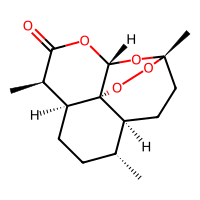
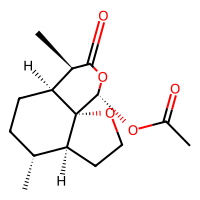
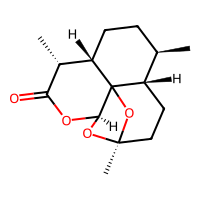
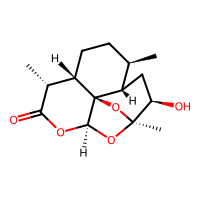
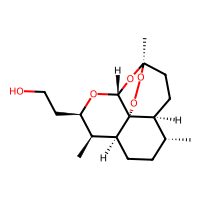
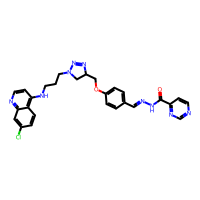
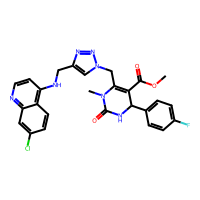
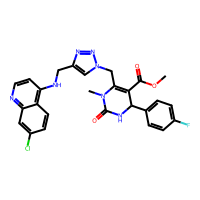
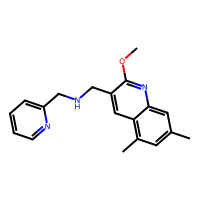
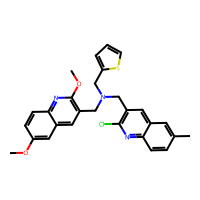

In [11]:
from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
dataset

In [12]:
#from rdkit.Chem import PandasTools
#PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
#dataset

# Agrupación

In [13]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      # Filter out None values from dataset.Structure before generating fingerprints
      valid_molecules = [mol for mol in dataset.Structure if mol is not None]
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in valid_molecules]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [14]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.4)

  0%|          | 0/186 [00:00<?, ?it/s]

In [15]:
# Number of clusters
len(np.unique(cluster_id))

66

In [16]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
dataset_cs = dataset[['Cmpd','SMILES','Structure', 'Activity']] # Selecciona algunas columnas y agrega una columna de número de cluster
dataset_cs['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
# dataset_cs.head() #observar los primeros diez elementos del dataframe

/tmp/ipykernel_1001/925022809.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset_cs['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.


In [17]:
# Histograma para las agrupaciones

cluster_counts = dataset_cs.groupby('Cluster_number')['Structure'].count().reset_index()

fig = px.bar(cluster_counts, x='Cluster_number', y='Structure',
             labels={'Cluster_number': 'Cluster Number', 'Structure': 'Number of Structures'},
             title='Number of Structures per Cluster')
fig.show()

In [18]:
# Actividad vs Cluster
fig = px.scatter(dataset_cs, y="Activity", x="Cluster_number",
                 title="Relación entre Actividad y Número de Cluster",
                 labels={"Activity": "Actividad", "Cluster_number": "Número de Cluster"},
                 height=700, width=1500)

app = molplotly.add_molecules(
    fig=fig,
    df=dataset_cs,
    smiles_col="SMILES",
    width=250,
    #caption_cols=["y_pred", "y_true", "Molecular Weight"],
    #show_coords=False
    )

app.run(port=8701, height=250)


/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [19]:
# Ordenamos por agrupación
dataset_cs_sorted = dataset_cs.sort_values(["Cluster_number"]).head(150)

# reinicia los indices da dataset:cs_sorted
dataset_cs_sorted = dataset_cs_sorted.reset_index(drop=True)

# generamos la cuadrícula
im = Draw.MolsToGridImage([x for x in dataset_cs_sorted["Structure"]][:125], maxMols=200,
                     legends=[str(x) for x in dataset_cs_sorted.Cluster_number], subImgSize=(350,350), molsPerRow=5)
# im # Visualizamos las moléculas con su respectivo Cluster

# MCS de cada cluster

In [20]:
# prompt: de dataset_cs filtra solo aquello elementos con Cluster_number ==1
cluster_number = 14

filtered_df = dataset_cs[dataset_cs['Cluster_number'] == cluster_number]

In [21]:
filtered_df['Activity'] = pd.to_numeric(filtered_df['Activity'], errors='coerce')
comparison_image = draw_multiple_mcs(filtered_df.SMILES)

if comparison_image:
  comparison_image
else:
    print("MCS not found or invalid SMILES provided.")

/tmp/ipykernel_1001/1888800126.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



-----------
Este es el cluster 14
-----------


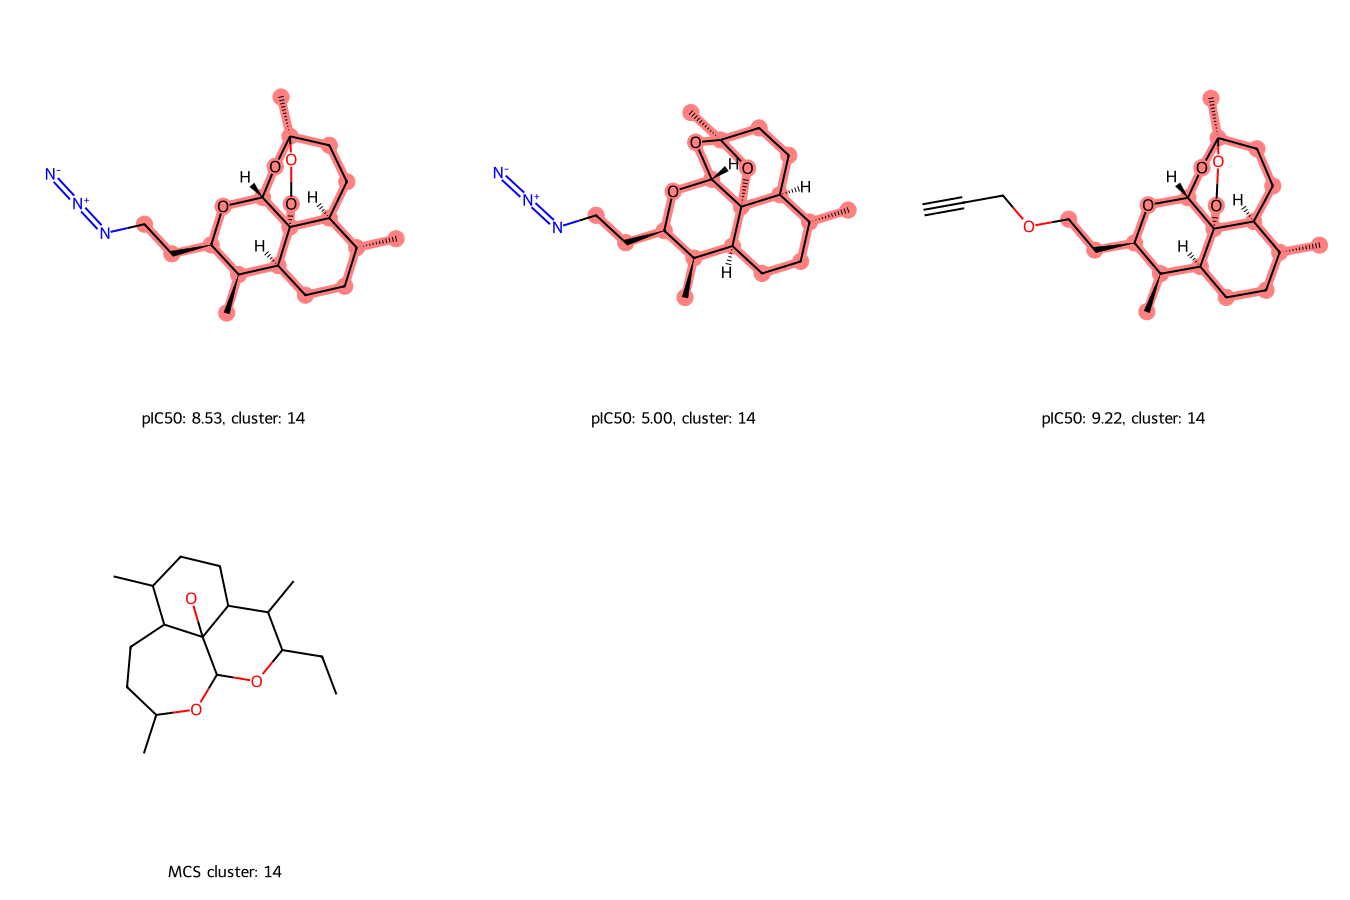

In [22]:
print('-----------')
print(f'Este es el cluster {cluster_number}')
print('-----------')
comparison_image

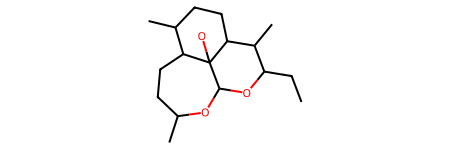

In [23]:
# prompt: guarda en una variable la estructura que se forma del mcs

mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
mcs_structure = mcs_mol
mcs_structure

# Todos los MCS de las agrupaciones

In [24]:
# Obtiene números de grupo únicos donde el número de estructuras es = 1 (No se obtiene MCS)
clusters = dataset_cs.groupby('Cluster_number')['Structure'].count().reset_index()
# Filtrar clústeres DataFrame en lugar de la lista
clusters = clusters[clusters['Structure'] == 1]['Cluster_number'].tolist()

In [25]:
# Obtenga números de grupo únicos donde el número de estructuras es >= 2 (Se obtienen los MCS)
clusters_to_process = dataset_cs.groupby('Cluster_number')['Structure'].count().reset_index()
# Filtrar clústeres DataFrame en lugar de la lista
clusters_to_process = clusters_to_process[clusters_to_process['Structure'] >= 2]['Cluster_number'].tolist()

In [26]:
# Itera cada grupo de moléculas, filtra el conjunto de datos principal para incluir solo moléculas que pertenecen al grupo actual y luego
#intenta encontrar la subestructura más común (MCS) entre estas moléculas.
mcs_results = {}  # Store MCS results for each cluster

for cluster_number in clusters_to_process:
    filtered_df = dataset_cs[dataset_cs['Cluster_number'] == cluster_number]
    mcs_mol, _, _, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        mcs_results[cluster_number] = mcs_mol
    else:
        mcs_results[cluster_number] = None
        print(f"No se logró encontrar el MCS para {cluster_number}")

In [27]:
# Asigna la MCS encontrada para el número de clúster 1 a la variable mcs_structure.
#mcs_results es un diccionario donde cada clave es un número de clúster y su valor es el objeto molécula RDKit
#que representa el MCS de ese clúster.
mcs_structure = mcs_results[3]
# mcs_structure

In [28]:
# Con mcs_results hace un dataframe donde contiene el objeto mol relacionado con sus cluster_number
mcs_results_df = pd.DataFrame(list(mcs_results.items()), columns=['Cluster_number', 'mol'])
# A mcs_results_df agrega la columna de cuantas moeculas tenia
mcs_results_df['molecule_count'] = mcs_results_df['Cluster_number'].map(dataset_cs.groupby('Cluster_number')['Structure'].count().to_dict())

In [29]:
# Genera una imagen de cuadrícula de la MCS para los primeros 125 grupos almacenados en mcs_results_df
dataset_cs['Activity'] = pd.to_numeric(dataset_cs['Activity'], errors='coerce')
a = Draw.MolsToGridImage([x for x in mcs_results_df["mol"]][:125], maxMols=200,
                     legends=['Cluster ID: ' + str(x) +
                              ', freq: ' + str(y) +
                              ', max pIC50: ' + str(z) +
                              ', min pIC50: ' + str(w)
                              for x, y, z, w in zip(mcs_results_df.Cluster_number,
                                                mcs_results_df.molecule_count,
                                                dataset_cs.groupby('Cluster_number')['Activity'].max(),
                                                dataset_cs.groupby('Cluster_number')['Activity'].min())],
                     subImgSize=(350,350), molsPerRow=3)
# a

/tmp/ipykernel_1001/1587341956.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [30]:
# De dataset_cs toma los valores donde cluster_number solo aparece una vez
cluster_counts = dataset_cs['Cluster_number'].value_counts()
single_occurrence_clusters = cluster_counts[cluster_counts == 1].index
dataset_cs_filtered = dataset_cs[dataset_cs['Cluster_number'].isin(single_occurrence_clusters)]
# Ordena  de manera crecienta con respecto a la columna Cluster_nummber a dataset_cs_filtered
dataset_cs_filtered = dataset_cs_filtered.sort_values('Cluster_number')
#dataset_cs_filtered

In [31]:
# Genera una imagen de cuadrícula para las agrupaciones que solo tienen una molécula
b = Draw.MolsToGridImage([x for x in dataset_cs_filtered["Structure"]][:125], maxMols=200,
                     legends=['Cluster ID: ' + str(x) for x in dataset_cs_filtered.Cluster_number],
                     subImgSize=(350,350), molsPerRow=3)
# b

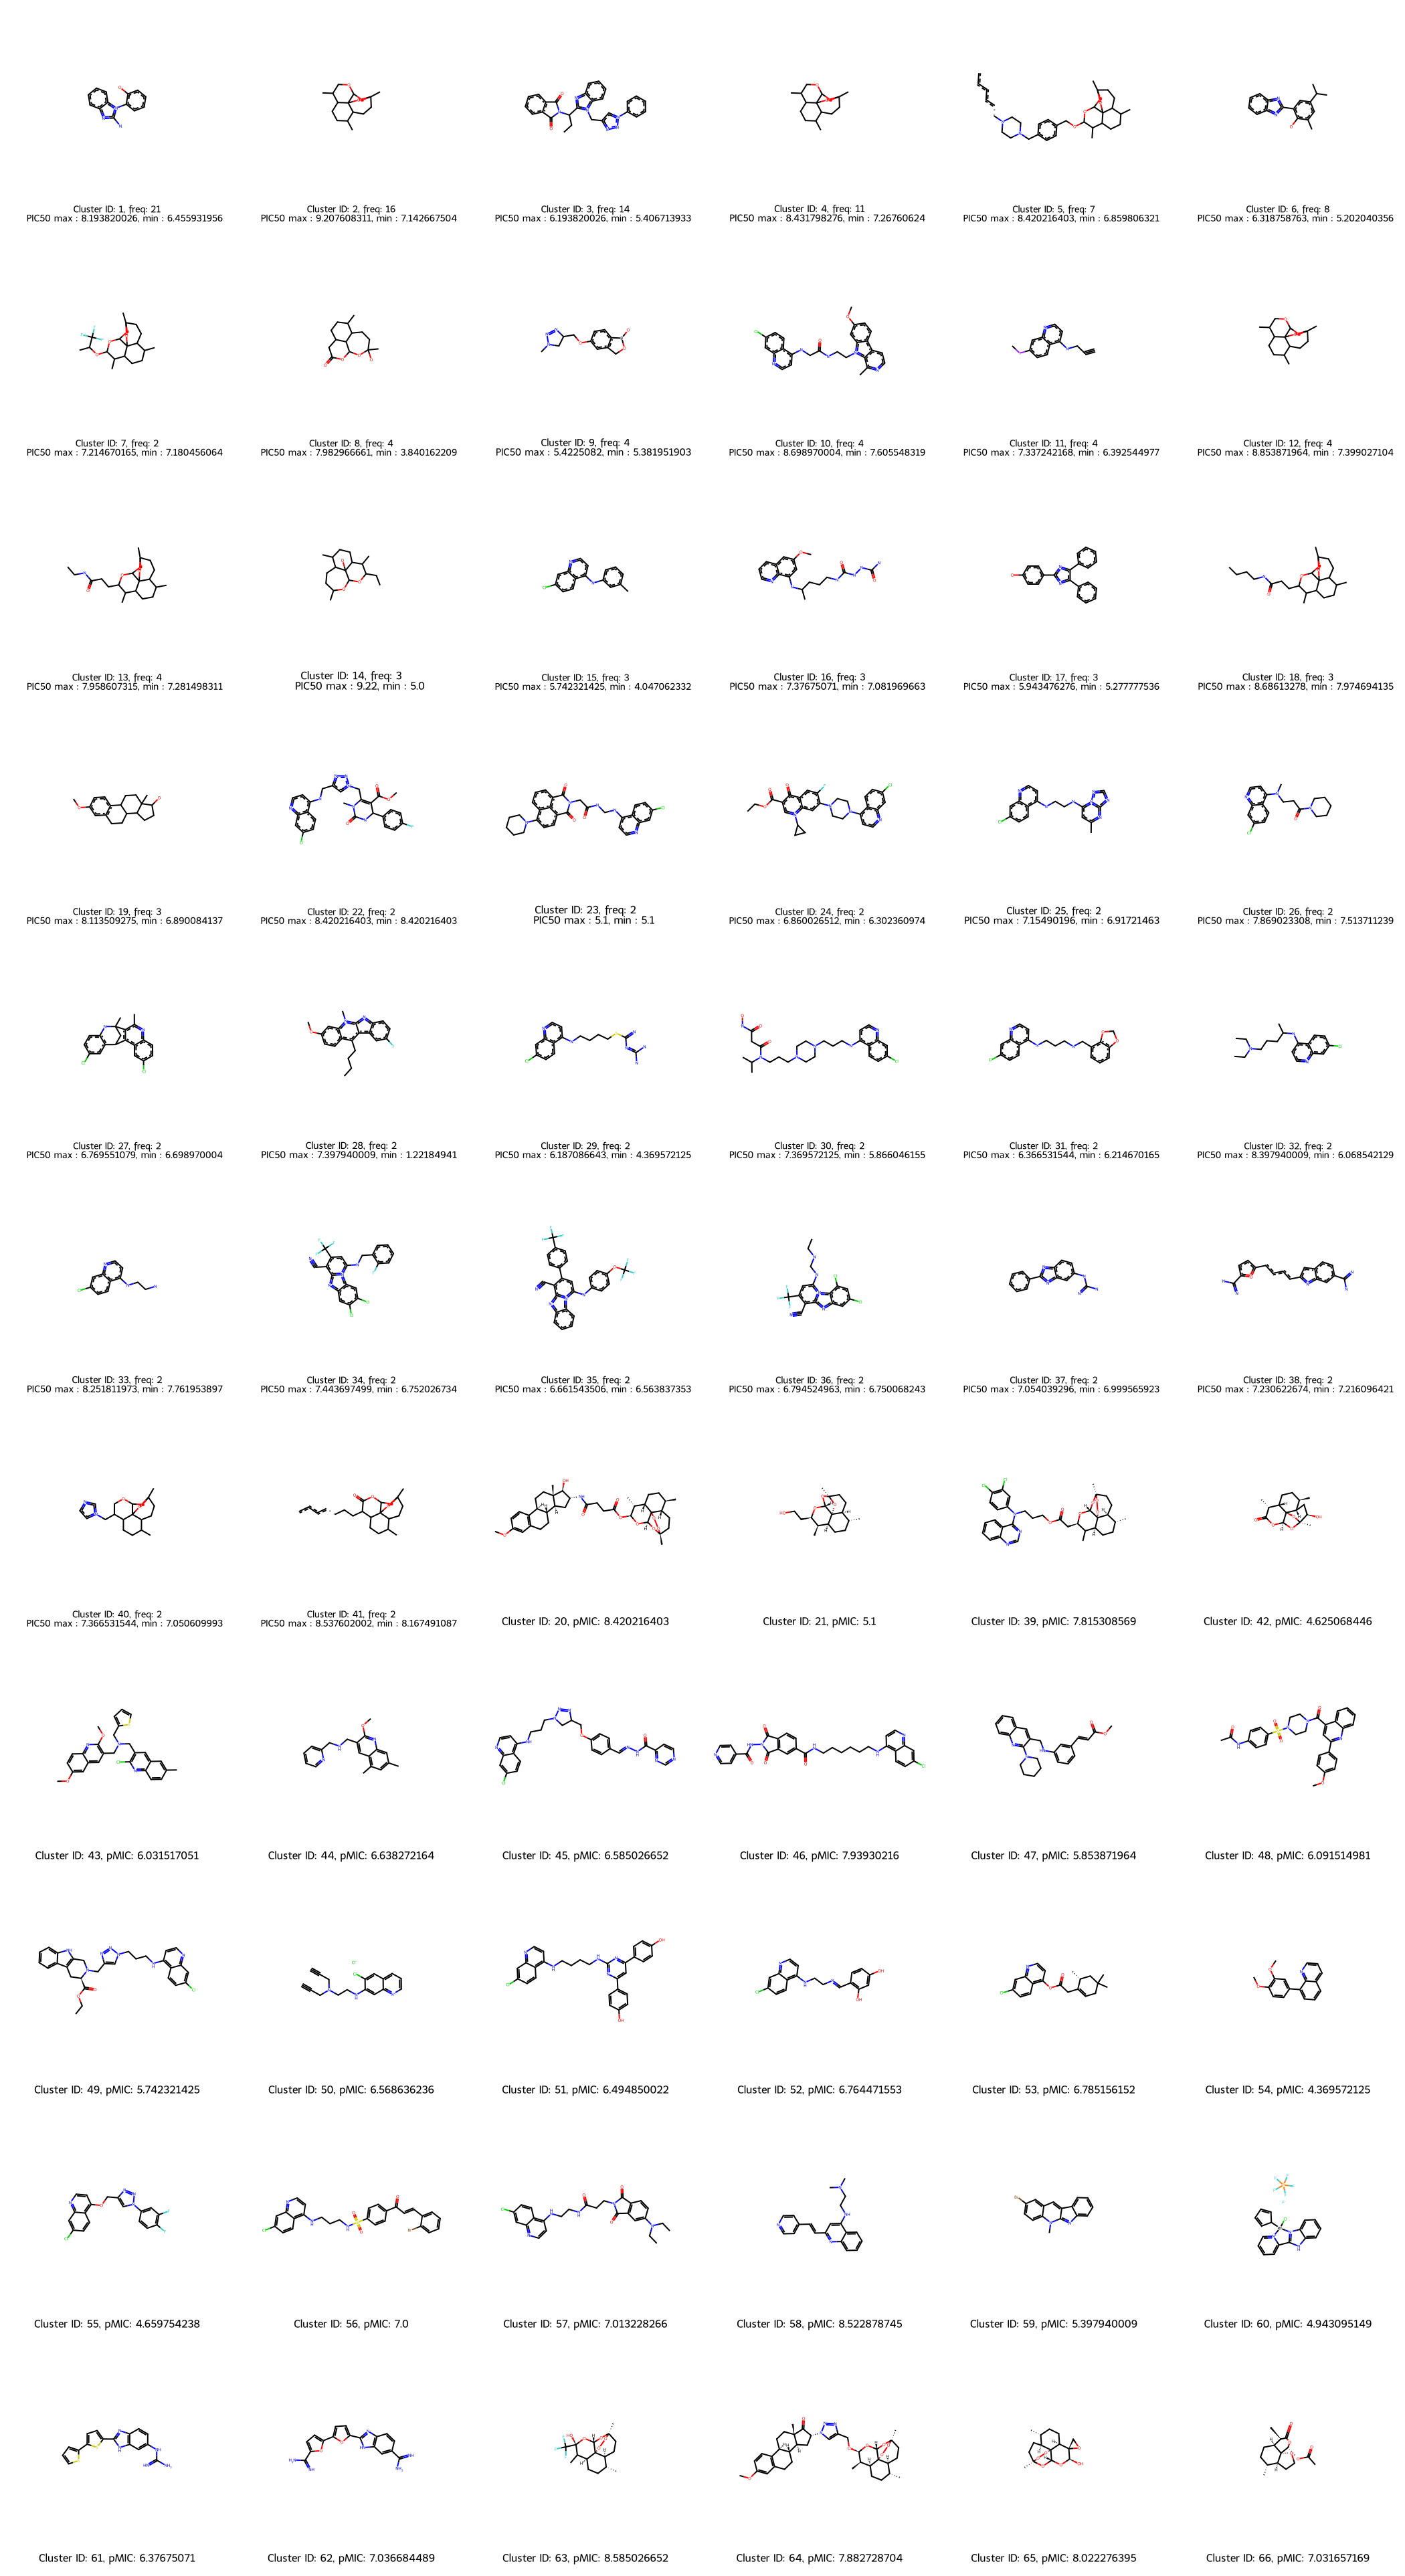

In [32]:
# Crea una lista vacía para legends
legends = []

# Agrega las leyendas para mcs_results_df
legends.extend([
  'Cluster ID: ' + str(x) +
    ', freq: ' + str(y) + '\n' +
    '´PIC50 '
    'max : ' + str(z) +
    ', min : ' + str(w)
    for x, y, z, w in zip(mcs_results_df.Cluster_number,
                        mcs_results_df.molecule_count,
                        dataset_cs.groupby('Cluster_number')['Activity'].max(),
                        dataset_cs.groupby('Cluster_number')['Activity'].min())
])

# Agrega las leyendas para dataset_cs_filtered
legends.extend([
    'Cluster ID: ' + str(x) + ', pMIC: ' + str(y)
    for x, y in zip(dataset_cs_filtered.Cluster_number, dataset_cs_filtered.Activity)
])

# Ahora use la lista aplanada de 'leyendas' en MolsToGridImage
combined_image = Draw.MolsToGridImage(
    [x for x in mcs_results_df["mol"]] + [x for x in dataset_cs_filtered["Structure"]],
    legends=legends,
    maxMols=200,
    subImgSize=(350, 350),
    molsPerRow=6
)
combined_image

# Matriz de similitud

In [33]:
# Para los smiles de dataset_cs_sorted calculca los indices de tanimoto de manera matricial

fps = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048) for mol in dataset_cs_sorted["Structure"]]

# Calculamos matriz de similitud de Tanimoto
tanimoto_matrix = np.zeros((len(fps), len(fps)))
for i in range(len(fps)):
    for j in range(i, len(fps)):  # Calculate only upper triangle, it's symmetric
        tanimoto_matrix[i, j] = DataStructs.TanimotoSimilarity(fps[i], fps[j])
        tanimoto_matrix[j, i] = tanimoto_matrix[i, j] # Fill the lower triangle

[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerator
[21:00:55] DEPRECATION WARNING: please use MorganGenerat

In [34]:
import plotly.express as px
fig = px.imshow(tanimoto_matrix,
                labels=dict(x="Molecule Index", y="Molecule Index", color="Tanimoto Similarity"),
                title="Tanimoto Similarity Matrix Heatmap 2",
                color_continuous_scale='PuRd', # You can change the color scale
                width=1000,  # Adjust width for better visualization
                height=800) # Adjust height for better visualization

fig.update_xaxes(side="bottom")  # Move x-axis label to the bottom
fig.show()

cluster ID: 1
pIC50: 7.327902142


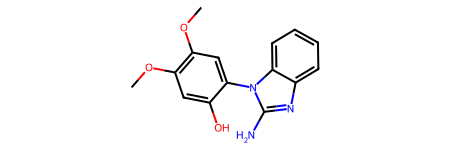

In [35]:
idx=15
print('cluster ID: '+ str(dataset_cs_sorted["Cluster_number"][idx]))
print('pIC50: ' + str(dataset_cs_sorted["Activity"][idx]))
m1 = dataset_cs_sorted["Structure"][idx]
m1

cluster ID: 3
pIC50: 5.46470588


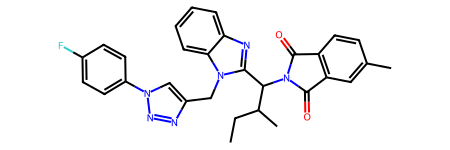

In [36]:
idx=39
print('cluster ID: '+ str(dataset_cs_sorted["Cluster_number"][idx]))
print('pIC50: ' + str(dataset_cs_sorted["Activity"][idx]))
m2 = dataset_cs_sorted["Structure"][idx]
m2

In [37]:
comparison_image = find_mcs_and_draw(m1, m2)
if comparison_image:
    comparison_image
else:
    print("MCS not found. Cannot generate comparison image.")

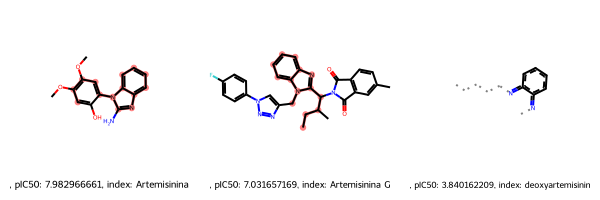

In [38]:
comparison_image

<div style="background-color:lightgreen; border-style: dotted;border-color: yellow;text-align:center;color:blue;font-size:20px;border-radius: 50px;padding: 20px 20px;"><strong> Tomado originalmente de
Gashaw M. Goshu, Ph.D. in Chemistry </strong></div> https://www.youtube.com/watch?v=-oHqQBUyrQ0 , adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM

